***Clustering and Annotation to Determine Cell Types***

In [36]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import os

In [37]:
from matplotlib import colors as mplc
_colors = ["lightgray", "royalblue", "gold"]
cmap = mplc.LinearSegmentedColormap.from_list("gray_blue_yellow", _colors)

SEED = 7
np.random.seed(SEED)
random.seed(SEED)

In [52]:
data_dir = "/Users/tank/Desktop/single_cell_edna/decontaminated"
output_dir = "/Users/tank/Desktop/single_cell_edna/results_intermediate/"

In [ ]:
input_file = os.path.join(data_dir, "pp_and_umap_data.h5ad")

adata = ad.read_h5ad(input_file)


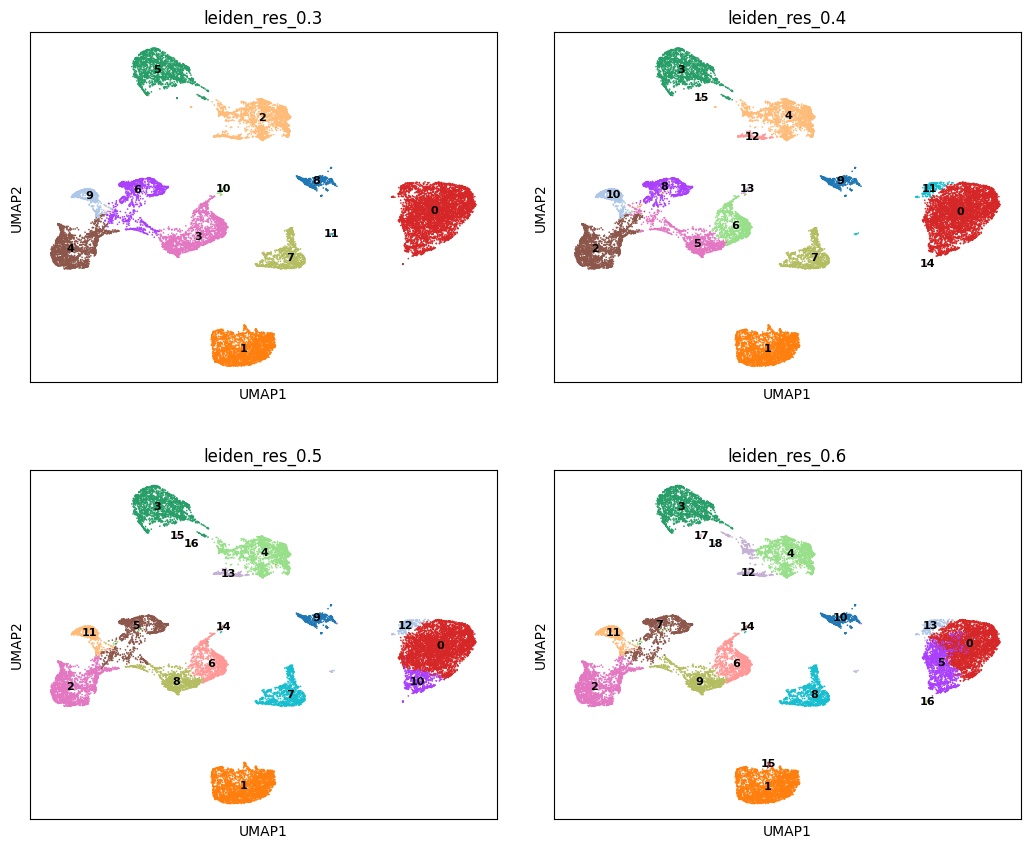

In [40]:
cols_to_drop = [c for c in adata.obs.columns if c.startswith("leiden_")]
adata.obs.drop(columns=cols_to_drop, inplace=True)
possible_res = [0.3, 0.4, 0.5, 0.6]
res_keys = []
for res in possible_res:
    key = f"leiden_res_{res:.1f}"
    sc.tl.leiden(adata, key_added=key, resolution=res, flavor="igraph")

    # sort clusters in order of size
    cluster_sizes = adata.obs[key].value_counts().sort_values(ascending=False)
    new_labels = {cluster: str(idx) for idx, cluster in enumerate(cluster_sizes.index)}
    adata.obs[key] = adata.obs[key].map(new_labels)

    res_keys.append(key)


sc.pl.umap(
    adata,
    color=res_keys,
    legend_loc="on data",
    legend_fontsize=8,
    ncols=2,              # Arranges the 4 plots into a 2x2 grid
    wspace=0.02            # Adjusts spacing between subplots
)


In [41]:
import scuva
scv =scuva

/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_6605/152565682.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby(["cluster", "condition"]).size()


condition  DMSO  StingI  anti_IL6_antibody  control_antibody_VEH  Total
cluster                                                                
0          1104    1475                798                  1232   4609
1           773     654                632                   775   2834
2           516     554                568                   411   2049
3           518     290                676                   464   1948
4           647     403                407                   432   1889
5           448     252                302                   211   1213
6           280     289                321                   266   1156
7           347     321                243                   226   1137
8           406     135                332                   206   1079
9           131     217                122                   195    665
10          101     251                114                   162    628
11          182     122                137                   113

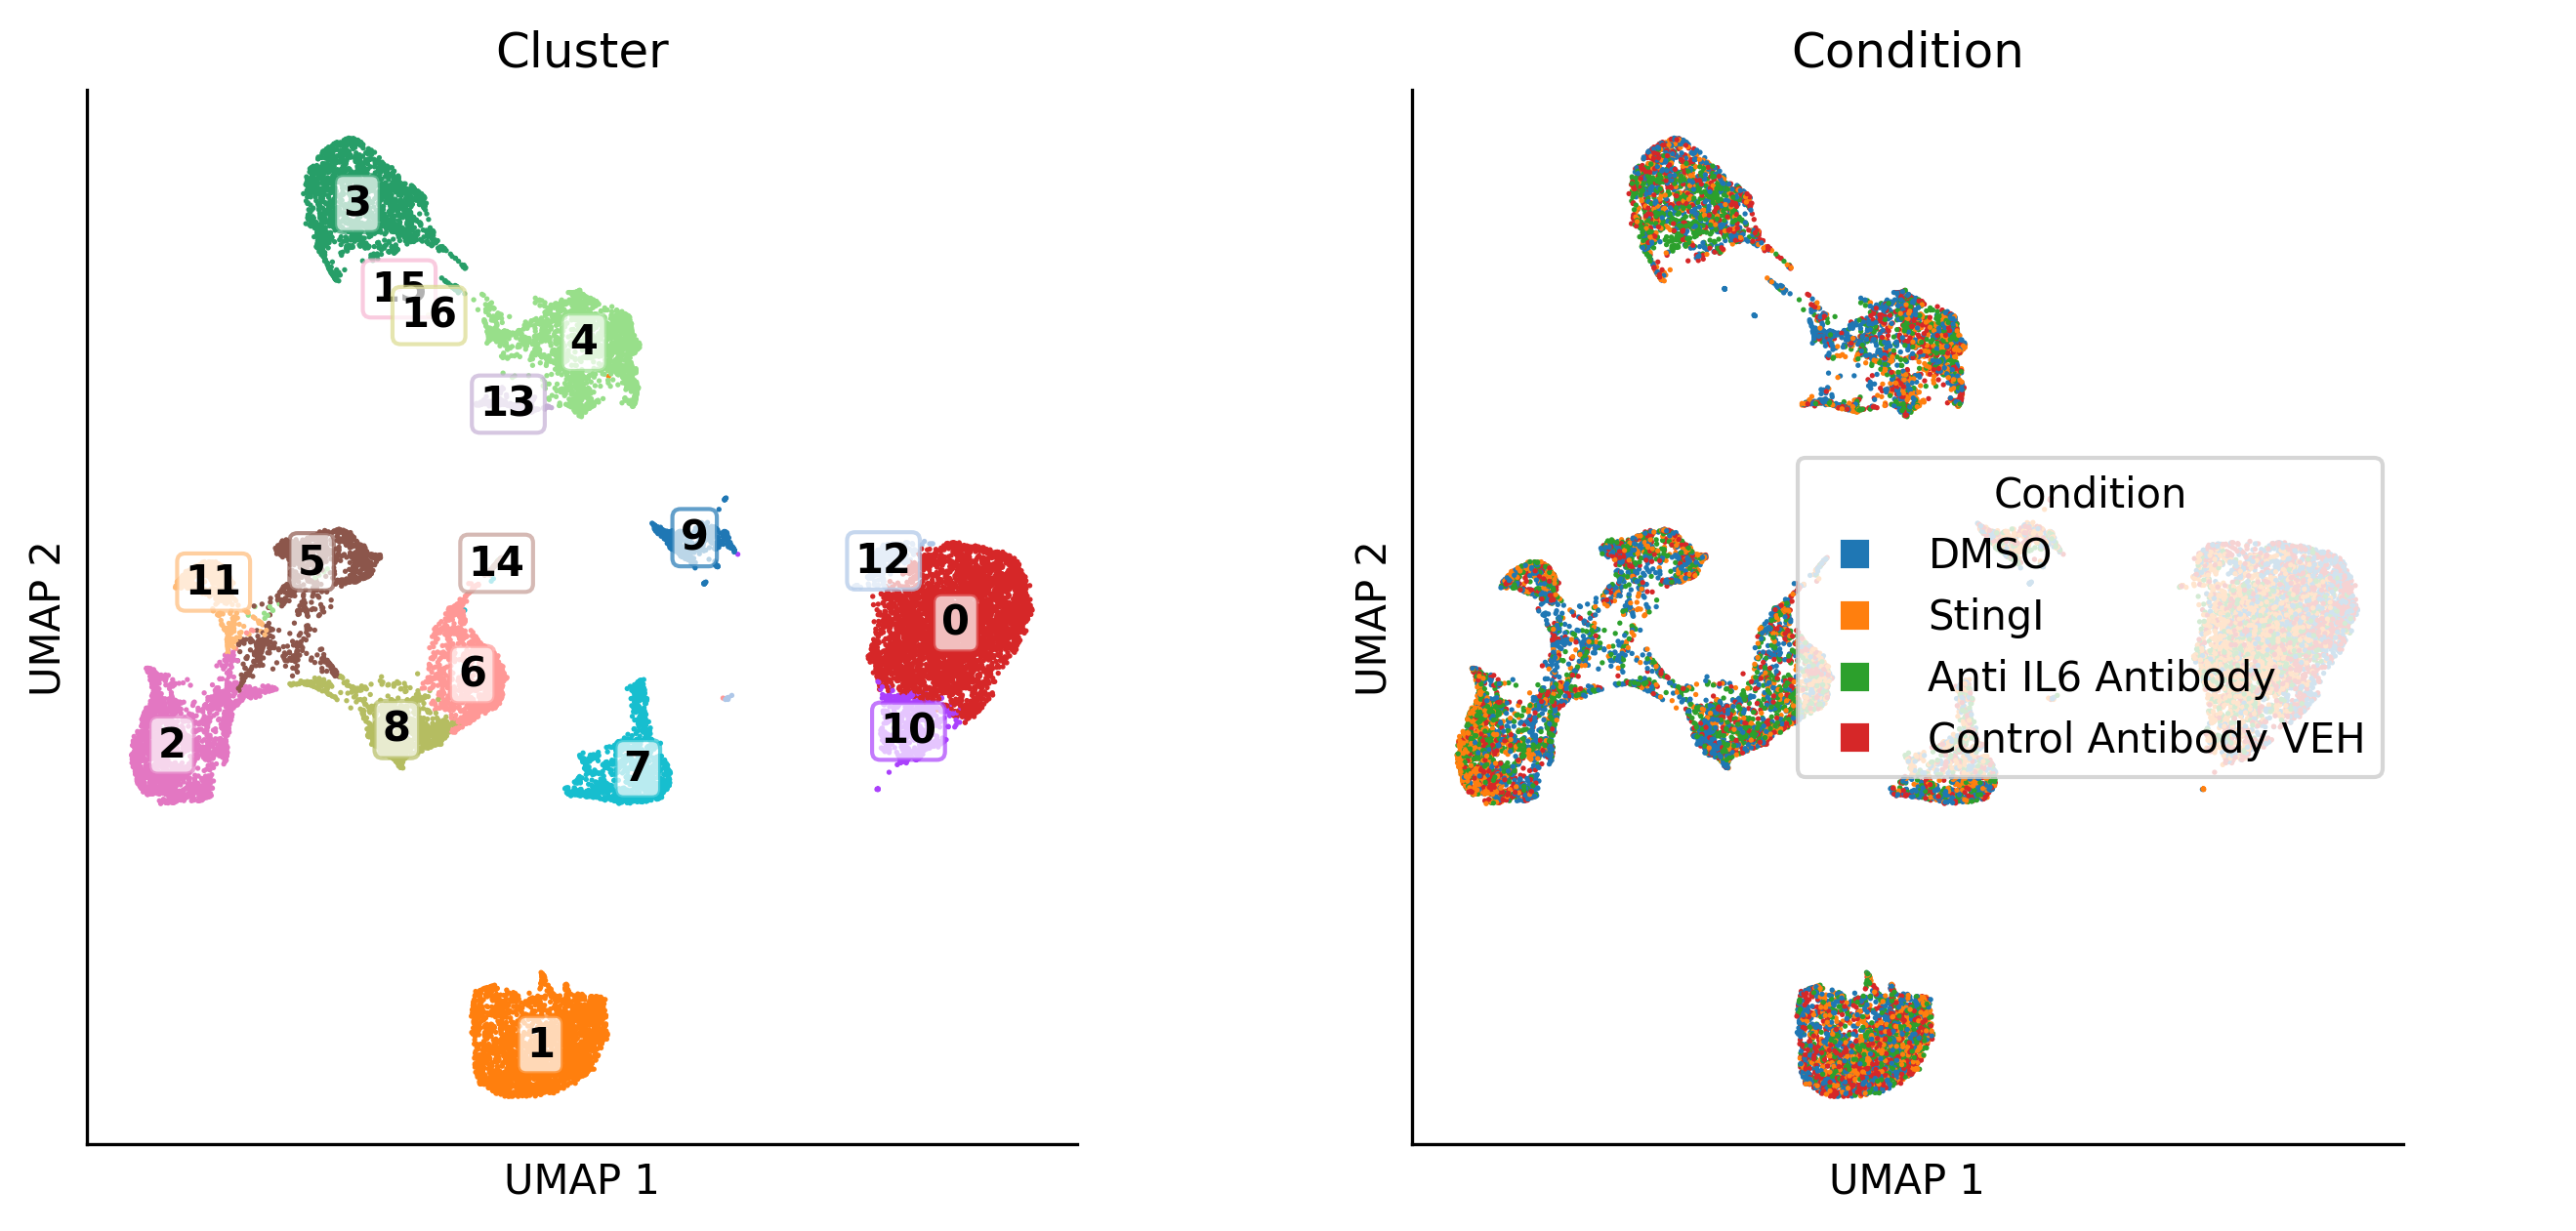

In [42]:
_resolution = "leiden_res_0.5"
adata.obs["cluster"] = adata.obs[_resolution]
adata.uns["cluster_colors"] = adata.uns[_resolution + "_colors"]
scv.multiple_umap(adata, ["cluster", "condition"], legend_loc=["on data", "right"], individual_figsize=(4, 4))

# generate a table of cell counts by cluster and sample
df = (
    adata.obs.groupby(["cluster", "condition"]).size()
    .reset_index().pivot(index="cluster", columns="condition", values=0)
    .fillna(0).astype(int).assign(Total=lambda x: x.sum(axis=1))
)
df.index = df.index.astype(int)
df = df.sort_index()
print(df)


In [ ]:
#It removes clusters 15 and 16, stores the filtered copy as adata, and preserves the original as adata_before_cluster_filter.
clusters_to_remove = ["15", "16"]
remove_mask = adata.obs["cluster"].astype(str).isin(clusters_to_remove)
adata_before_cluster_filter = adata
adata = adata_before_cluster_filter[~remove_mask].copy()

print(f"Removed {int(remove_mask.sum())} cells from clusters {clusters_to_remove}")
print(f"Remaining cells: {adata.n_obs}")


Removed 20 cells from clusters ['15', '16']
Remaining cells: 20403


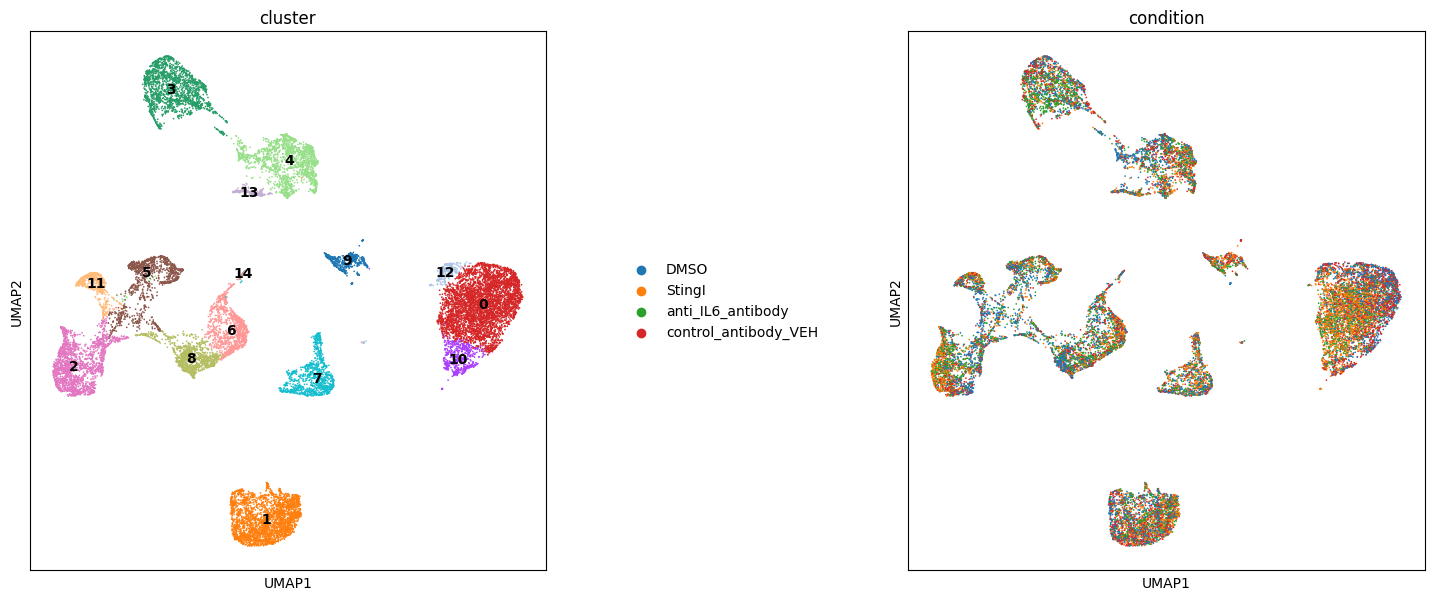

In [78]:
import matplotlib.pyplot as plt
import scanpy as sc

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.subplots_adjust(wspace=0.7)

sc.pl.umap(
    adata, color="cluster",
    legend_loc="on data", ax=axes[0], show=False,
)

sc.pl.umap(
    adata, color="condition",
    legend_loc="right margin", ax=axes[1], show=False,
)

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
    handles, labels,
    loc="center right",
    bbox_to_anchor=(-0.15, 0.5),
    frameon=False,
)

plt.show()

In [44]:
def get_expression_by_obs(anndata, column):
    sc.tl.rank_genes_groups(anndata, groupby=column, method="wilcoxon")
    df = sc.get.rank_genes_groups_df(anndata, group=None)
    df.rename(columns={"group": column}, inplace=True)
    df_pct_expr = []
    for c in df[column].unique():
        subset = anndata[anndata.obs[column] == c]
        percent_expressing = ((subset.layers["counts"] > 0).sum(axis=0) / len(subset)).A1 * 100
        average_expression = subset.X.mean(axis=0).A1
        df_pct_expr.append(pd.DataFrame({
            column: c,
            "names": subset.var_names, 
            "percent_expressing": percent_expressing,
            "average_expression": average_expression,
        }).set_index([column, "names"]))
        
    df = df.join(pd.concat(df_pct_expr), on=[column, "names"], how="left")
    if pd.to_numeric(df[column], errors="coerce").notna().all():
        df = df.astype({column: int})
    return df.sort_values([column, "scores"], ascending=[True, False])

ebc = get_expression_by_obs(adata, "cluster")
adata.uns["expression_by_cluster"] = ebc

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [45]:
ebc

,cluster,names,scores,logfoldchanges,pvals,pvals_adj,percent_expressing,average_expression
42993,0,Ighm,95.171906,5.253813,0.000000e+00,0.000000e+00,96.463441,2.217111
42994,0,Ighd,93.901985,6.131829,0.000000e+00,0.000000e+00,93.621176,1.825452
42995,0,Cd79a,93.271698,5.341064,0.000000e+00,0.000000e+00,94.011716,1.762015
42996,0,Cd19,91.434395,5.376663,0.000000e+00,0.000000e+00,92.644825,1.537996
42997,0,Cd37,84.328712,4.037329,0.000000e+00,0.000000e+00,88.934693,1.386455
...,...,...,...,...,...,...,...,...
214960,14,Tapbp,-10.176874,-4.192845,2.515105e-24,1.638363e-21,5.494505,0.058616
214961,14,Ddx17,-11.014929,-3.964550,3.237939e-28,2.442258e-25,7.692308,0.076833
214962,14,Ly6e,-11.029002,-3.760350,2.769201e-28,2.204746e-25,10.989011,0.123803
214963,14,H2-K1,-11.615145,-4.896574,3.452018e-31,3.533633e-28,4.395604,0.048175


In [49]:
import cellxgene_census

In [53]:
census_version = "2025-01-30"
tissue = "lung"
filename = f"mouse_{tissue}_avg_expr_{census_version}.csv"

with cellxgene_census.open_soma(census_version=census_version) as census:
    mouse_lung = cellxgene_census.get_anndata(
    census=census,
    organism="Mus musculus",
    obs_value_filter=f"tissue == '{tissue}'",
    obs_column_names=["cell_type"],
)

sc.pp.normalize_total(mouse_lung)
sc.pp.log1p(mouse_lung)

X_dense = mouse_lung.X.toarray()
expr_df = pd.DataFrame(
    X_dense,
    index=mouse_lung.obs_names,
    columns=mouse_lung.var["feature_name"],
)
expr_df["cell_type"] = mouse_lung.obs["cell_type"].values

avg_expr = expr_df.groupby("cell_type").mean()
avg_expr.to_csv(filename)

import re

top5_celltypes = {}

common_genes = list(set(ebc.names.unique()).intersection(set(avg_expr.columns)))
ref = avg_expr.loc[avg_expr.var(axis=1) > 0, common_genes]
n_clusters = len(adata.obs["cluster"].unique())
cluster_sizes = adata.obs.groupby("cluster").size()
for i in range(n_clusters):
    scores_i = ebc.loc[(ebc.cluster == i)].set_index("names")["scores"][common_genes]
    mat = np.vstack([scores_i.values, ref.values])
    corr = pd.Series(
        np.corrcoef(mat)[0, 1:],
        index= ref.index
    )
    top5_celltypes[i] = corr.sort_values(ascending=False).head(5)
    print(f"{i:2d}: {cluster_sizes[str(i)]:4d} cells")
    for cell in top5_celltypes[i].index:
        print(f' {re.sub("lung", "", cell)} ({top5_celltypes[i][cell]:.2f})')

/Users/tank/miniconda3/envs/single_cell/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/Users/tank/miniconda3/envs/single_cell/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_6605/1594239172.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_expr = expr_df.groupby("cell_type").mean()


 0: 4609 cells
 B cell (0.13)
 CD4-positive, alpha-beta T cell (-0.06)
 CD8-positive, alpha-beta T cell (-0.06)
 mature NK T cell (-0.06)
 regulatory T cell (-0.08)
 1: 2834 cells
 CD4-positive, alpha-beta T cell (0.22)
 regulatory T cell (0.22)
 mature NK T cell (0.22)
 CD8-positive, alpha-beta T cell (0.22)
 T cell (0.17)
 2: 2049 cells
 bronchial smooth muscle cell (0.37)
 smooth muscle cell of the pulmonary artery (0.29)
 vein endothelial cell (0.27)
 capillary endothelial cell (0.25)
 endothelial cell of artery (0.22)
 3: 1948 cells
 alveolar macrophage (0.58)
 hematopoietic cell (0.43)
  macrophage (0.42)
 non-classical monocyte (0.41)
 classical monocyte (0.40)
 4: 1889 cells
 myeloid dendritic cell (0.37)
 dendritic cell (0.35)
  macrophage (0.34)
 non-classical monocyte (0.32)
 intermediate monocyte (0.32)
 5: 1213 cells
 fibroblast of  (0.47)
 adventitial cell (0.45)
 pericyte (0.34)
 pulmonary interstitial fibroblast (0.33)
 mesenchymal cell (0.30)
 6: 1156 cells
 pulmonary 

/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_6605/1594239172.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_sizes = adata.obs.groupby("cluster").size()


In [54]:
annotation_guess = pd.DataFrame(columns=["cell count", "top 5 cells (cellxgene expression)", "top 30 genes"])
for i in range(n_clusters):
    top5_cells = " | ".join([f"{index} ({row:0.3f})" for index, row in top5_celltypes[i].items()])
    annotation_guess.loc[i] = [
        cluster_sizes[str(i)], top5_cells, ", ".join(ebc[ebc.cluster == i].names.head(30))
    ]
annotation_guess.to_csv(os.path.join(output_dir, "annotation_guess.csv"), index_label="cluster")
annotation_guess

,cell count,top 5 cells (cellxgene expression),top 30 genes
0,4609,"B cell (0.126) | CD4-positive, alpha-beta T ce...","Ighm, Ighd, Cd79a, Cd19, Cd37, Pax5, H2-Ob, Cd..."
1,2834,"CD4-positive, alpha-beta T cell (0.225) | regu...","Lat, Skap1, Lck, Thy1, Arhgap45, Spn, Itk, Cd3..."
2,2049,bronchial smooth muscle cell (0.368) | smooth ...,"Egfl7, Shank3, Ace, Calcrl, Thbd, Acvrl1, Cldn..."
3,1948,alveolar macrophage (0.585) | hematopoietic ce...,"Chil3, Cd9, Ctss, Axl, Ctsd, Cebpb, Mpeg1, Sir..."
4,1889,myeloid dendritic cell (0.373) | dendritic cel...,"Csf2ra, Cst3, Pirb, Psap, Ctss, Tyrobp, Prkcd,..."
5,1213,fibroblast of lung (0.467) | adventitial cell ...,"Bgn, Col1a2, Col3a1, Gsn, Col1a1, Mgp, Ltbp4, ..."
6,1156,pulmonary alveolar type 2 cell (0.155) | respi...,"Sftpb, Nkx2-1, Slc34a2, Sftpc, Sftpa1, Dram1, ..."
7,1137,ciliated columnar cell of tracheobronchial tre...,"Cyp2f2, Cbr2, Scgb1a1, Wfdc2, Hp, Pigr, Cp, Ce..."
8,1079,pulmonary alveolar type 2 cell (0.504) | pulmo...,"Sftpc, Sftpa1, Cxcl15, Sftpb, Slc34a2, Sftpd, ..."
9,665,plasma cell (0.347) | lung neuroendocrine cell...,"Igkc, Jchain, Xbp1, Mzb1, Txndc5, Igha, Edem1,..."


In [56]:
import scuva
scv = scuva



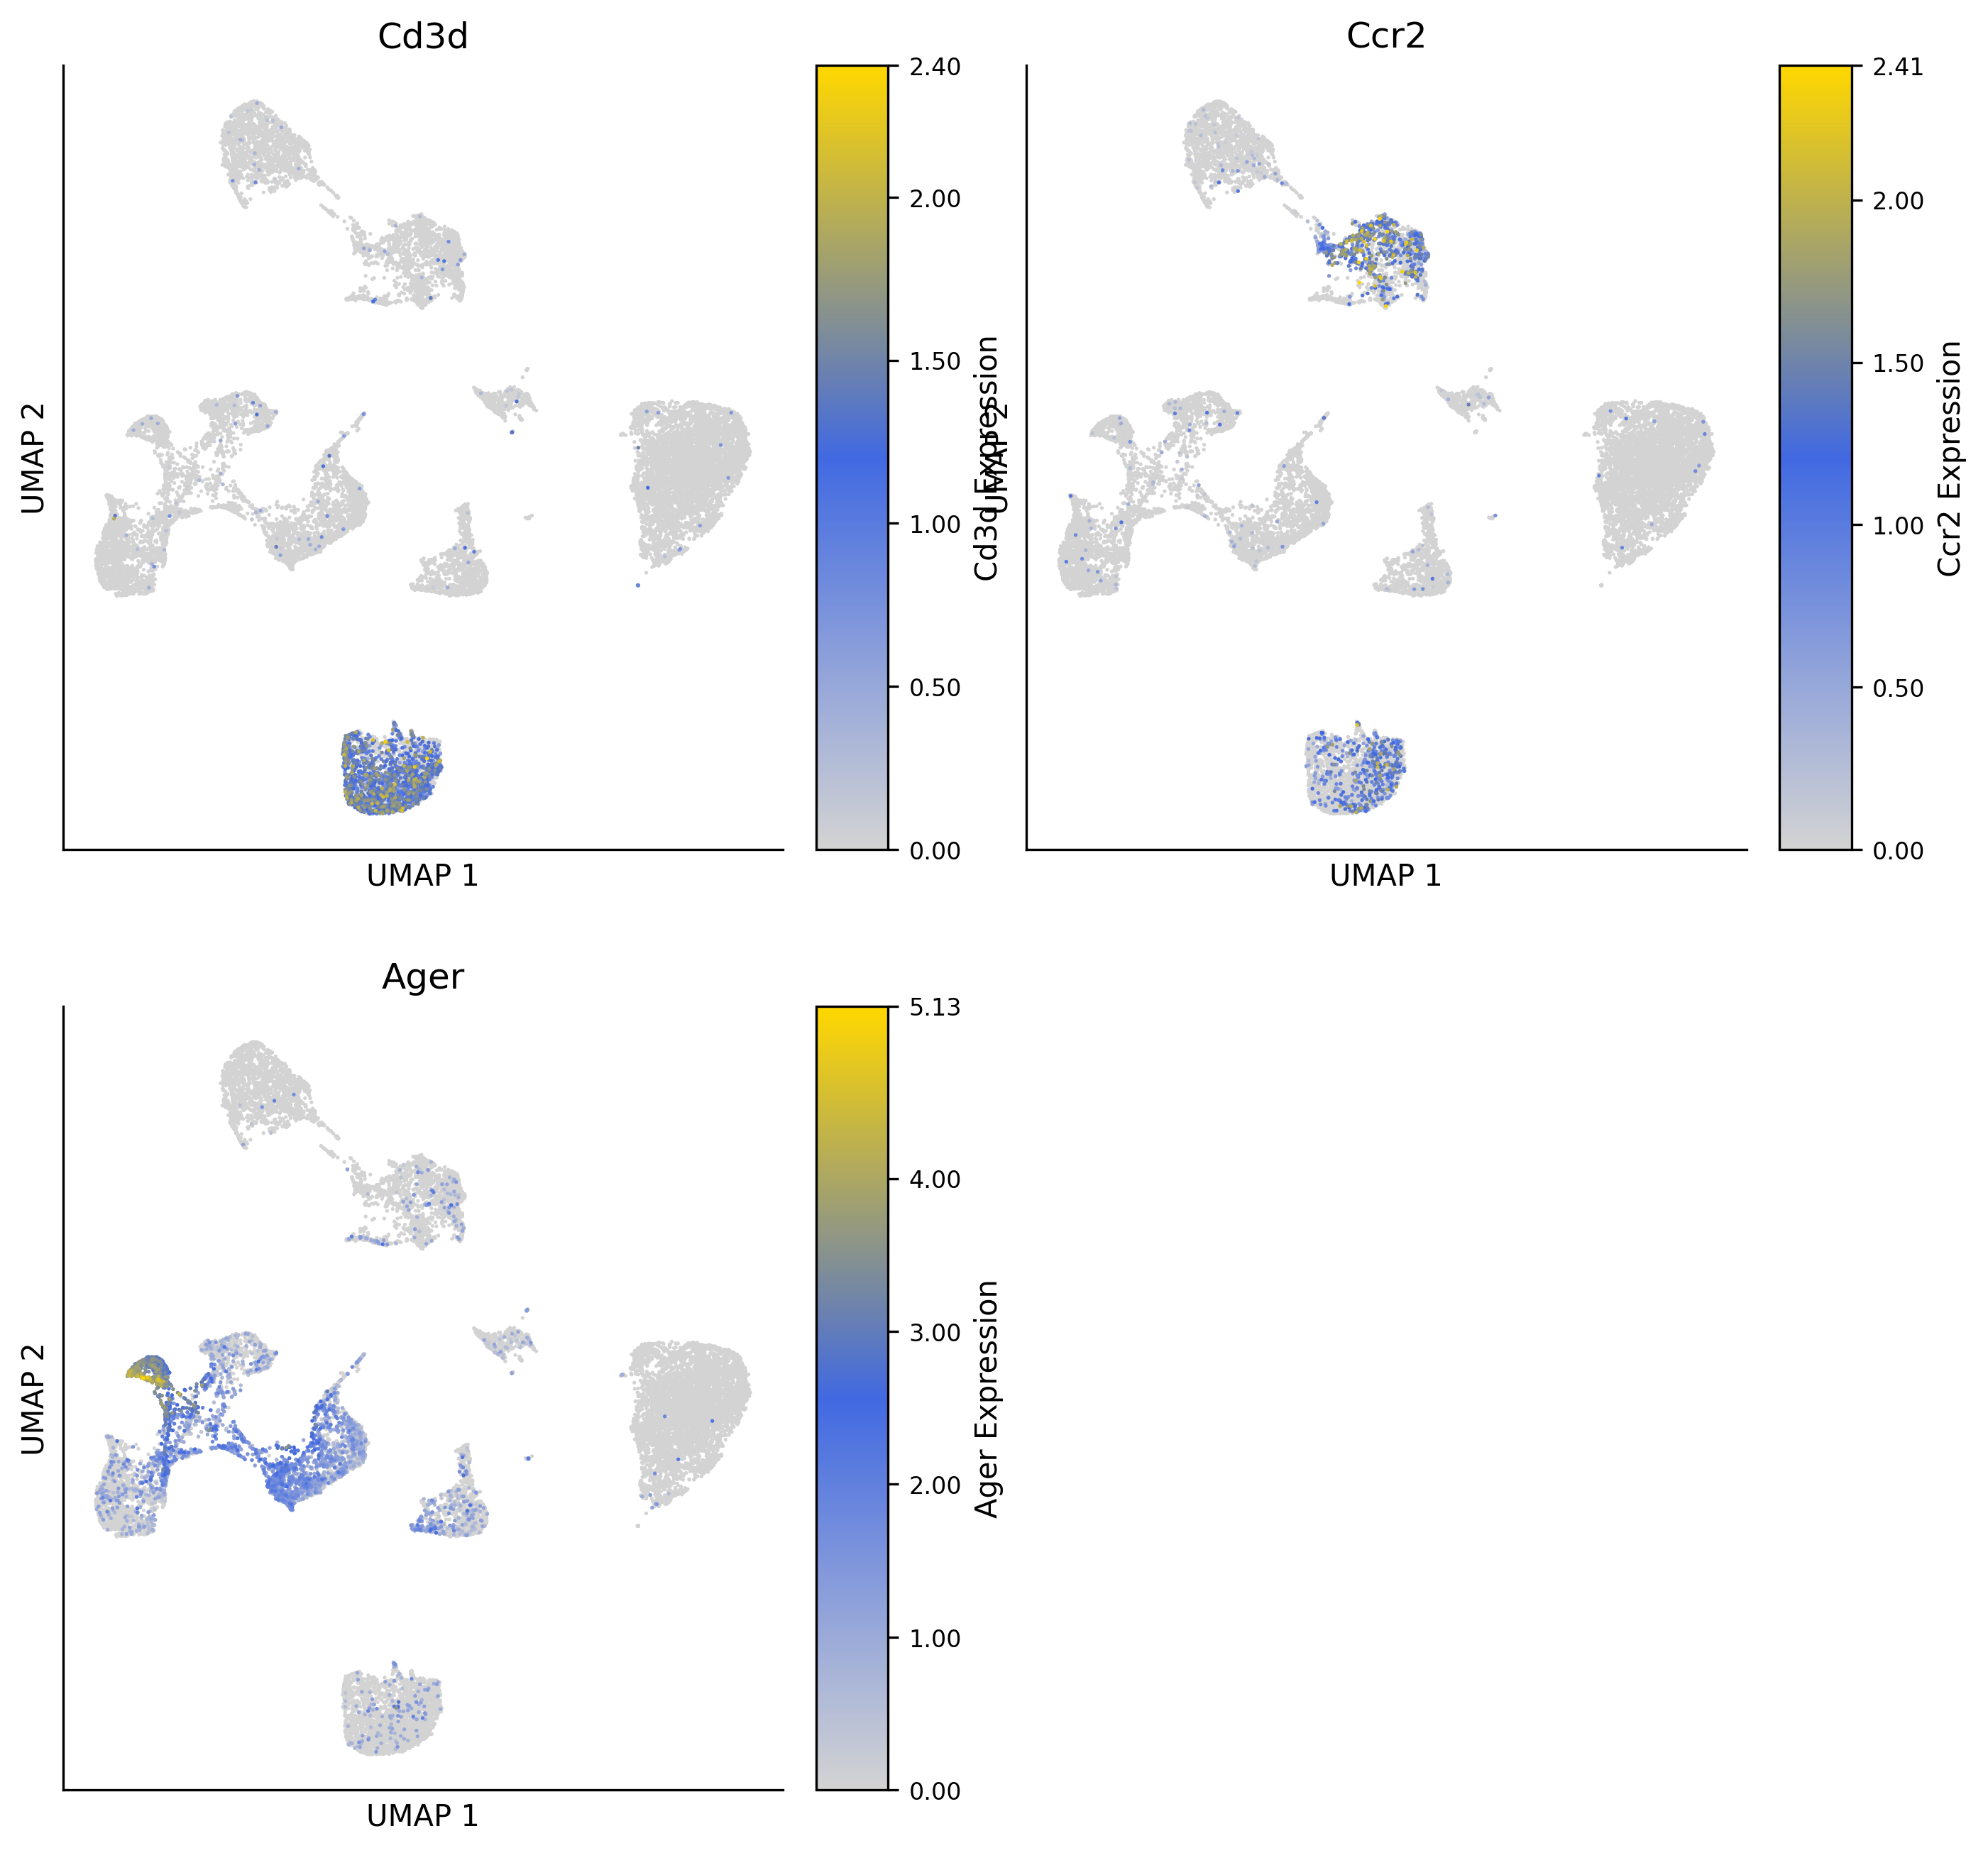

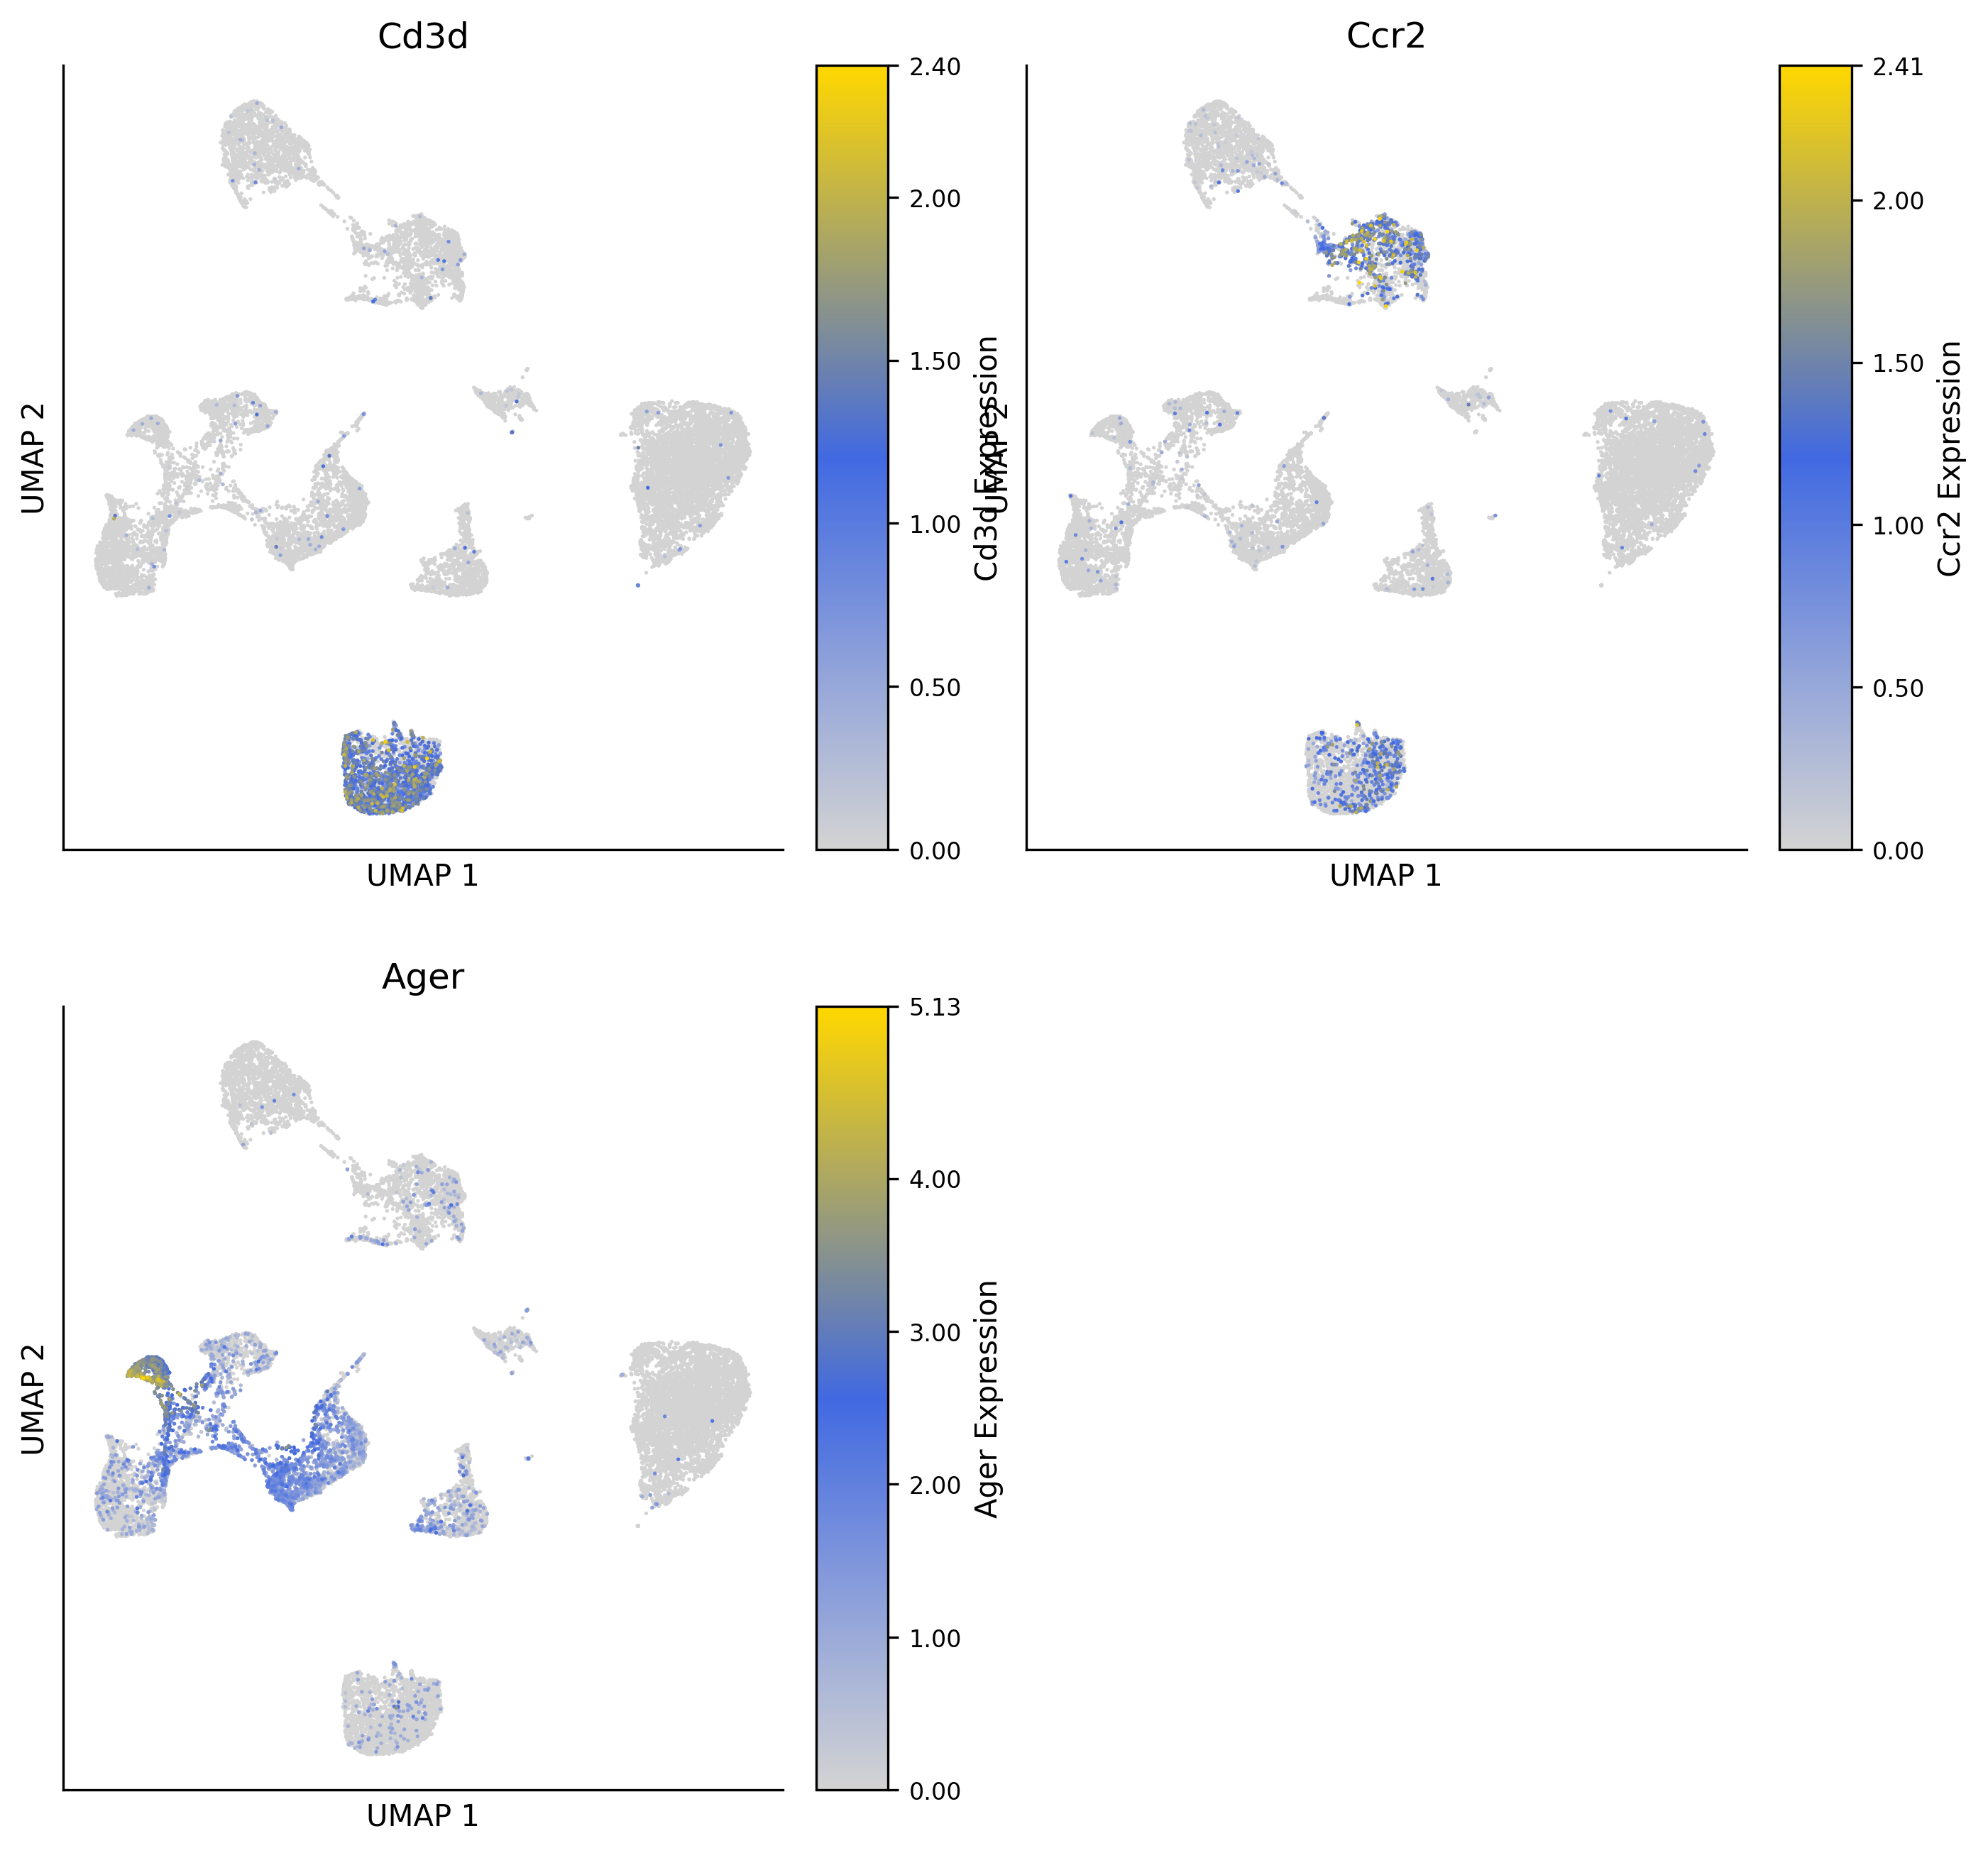

In [72]:
scuva.multiple_umap(
    adata,
    ["Cd3d", "Ccr2", "Ager"],
    cmap=cmap,
)

In [ ]:
# Save the current filtered analysis for the Shiny explorer.
from pathlib import Path

shiny_output = Path(output_dir)
shiny_output.mkdir(parents=True, exist_ok=True)
if "cluster" not in adata.obs:
    raise ValueError("Run the clustering cell before exporting.")
if adata.obs["cluster"].astype(str).isin(["15", "16"]).any():
    raise ValueError("Run the cluster 15/16 removal cell before exporting.")

shiny_target = shiny_output / "clustered_filtered.h5ad"
shiny_temporary = shiny_target.with_name("." + shiny_target.name + ".tmp")
adata.uns["shiny_export"] = {
    "source": "clustering_and_annotation.ipynb",
    "removed_clusters": ["15", "16"],
    "note": "Exported from the current notebook adata; existing embeddings retained.",
}
adata.write_h5ad(shiny_temporary)
shiny_temporary.replace(shiny_target)
(
    adata.obs.groupby(["cluster", "condition"], observed=True)
    .size().rename("cell_count").reset_index()
    .to_csv(shiny_output / "cell_counts_by_cluster_condition.csv", index=False)
)
print(f"Saved {adata.n_obs:,} cells to {shiny_target}. Refresh the Shiny app to load updates.")
